# Step 2 — Building Footprints → Estimated Square Footage (2024–25)

This notebook estimates the floor area of every **operational** school from Step 1 by finding the building its map
point sits on, using **Microsoft US Building Footprints** — the same source the prototype used.

**Input:** `data/interim/schools_2024_25.csv` (from Step 1).
**Output:** `data/interim/school_sqft_2024_25_<scope>.csv` — one row per operational school in the chosen scope.

## Source: Microsoft US Building Footprints

| | |
|---|---|
| Repository (file list and links) | https://github.com/microsoft/USBuildingFootprints |
| Version | Release 2 (`usbuildings-v2`) — 129.6 million buildings |
| Coverage | **50 states + District of Columbia**, one zipped GeoJSON file per state. No U.S. territories. |
| What each building has | outline (polygon), `release`, and `capture_dates_range` — the date(s) of the imagery it was drawn from, when known |
| Imagery | 2019–2020 in Microsoft's focal update area; elsewhere older imagery, averaging about 2012 (per the repository) |
| File sizes | unzipped from 22.5 MB (DC) to 3.35 GB (California); Texas 2.83 GB, Florida 2.01 GB |
| License | Open Data Commons Open Database License (ODbL) |

Microsoft's newer *Global* building dataset (updated 2026) was tested on New York and **not** used: it is missing
many buildings in dense city cores — for example, most of Manhattan.

## Method

For each school:
1. Find the **building whose outline contains the school's point**.
2. Measure that outline's area in an **equal-area map projection** (EPSG:6933) and convert m² to square feet. An
   equal-area projection keeps areas exact in every state; a projection designed for one state would distort areas
   elsewhere.
3. Apply the **minimum of 180 sq ft per student**: if the footprint is smaller than students × 180, or no building is
   found, use students × 180.

The same rule and the same measurement are applied to every state.

The known limits of this method are **called out, not fixed** — see section 8.

## How to run

1. In **section 2**, choose the scope: one state (default `NY`) or every state.
2. Run all cells. Each state file is downloaded, processed and **deleted** before the next one, so at most one state
   file is on disk at a time. Only buildings within 150 m of a school are loaded into memory. Results are saved per
   state, so an interrupted run continues where it stopped.

The full national run downloads 4.8 GB of zipped files (34.4 GB unzipped, read straight from the zip) and takes
several hours; it is written and documented but was not run here. The largest files (California, Texas,
Florida) were not test-run.

## 1. Setup

In [1]:
import shutil
import time
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

print(f"pandas {pd.__version__} | geopandas {gpd.__version__} | numpy {np.__version__}")

pandas 3.0.2 | geopandas 1.1.0 | numpy 2.4.4


In [2]:
def check(condition: bool, failure_message: str) -> None:
    # Stops the notebook with a plain-language message instead of continuing with bad data.
    if not condition:
        raise ValueError(failure_message)

## 2. Choose what to run

- `RUN_SCOPE = "one_state"` processes the schools physically located in `STATE_TO_RUN` (postal code, e.g. `"NY"`).
  Bureau of Indian Education schools are included in the state they sit in.
- `RUN_SCOPE = "all"` processes every operational school, one state file after another.

In [3]:
RUN_SCOPE = "one_state"  # "one_state" or "all"
STATE_TO_RUN = "NY"  # used only when RUN_SCOPE == "one_state"

In [4]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SCHOOLS_FILE = PROJECT_ROOT / "data" / "interim" / "schools_2024_25.csv"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
TEMP_DOWNLOAD_DIR = (
    PROJECT_ROOT / "data" / "raw" / "footprints_usbuildings_v2_tmp"
)  # one state file at a time
STATE_RESULTS_DIR = INTERIM_DIR / "footprint_state_results_usbuildings_v2"

# File names exactly as listed in the USBuildingFootprints README (50 states + DC).
FOOTPRINT_BASE_URL = "https://minedbuildings.z5.web.core.windows.net/legacy/usbuildings-v2"
FOOTPRINT_FILE_BY_STATE = {
    "AL": "Alabama",
    "AK": "Alaska",
    "AZ": "Arizona",
    "AR": "Arkansas",
    "CA": "California",
    "CO": "Colorado",
    "CT": "Connecticut",
    "DE": "Delaware",
    "DC": "DistrictofColumbia",
    "FL": "Florida",
    "GA": "Georgia",
    "HI": "Hawaii",
    "ID": "Idaho",
    "IL": "Illinois",
    "IN": "Indiana",
    "IA": "Iowa",
    "KS": "Kansas",
    "KY": "Kentucky",
    "LA": "Louisiana",
    "ME": "Maine",
    "MD": "Maryland",
    "MA": "Massachusetts",
    "MI": "Michigan",
    "MN": "Minnesota",
    "MS": "Mississippi",
    "MO": "Missouri",
    "MT": "Montana",
    "NE": "Nebraska",
    "NV": "Nevada",
    "NH": "NewHampshire",
    "NJ": "NewJersey",
    "NM": "NewMexico",
    "NY": "NewYork",
    "NC": "NorthCarolina",
    "ND": "NorthDakota",
    "OH": "Ohio",
    "OK": "Oklahoma",
    "OR": "Oregon",
    "PA": "Pennsylvania",
    "RI": "RhodeIsland",
    "SC": "SouthCarolina",
    "SD": "SouthDakota",
    "TN": "Tennessee",
    "TX": "Texas",
    "UT": "Utah",
    "VT": "Vermont",
    "VA": "Virginia",
    "WA": "Washington",
    "WV": "WestVirginia",
    "WI": "Wisconsin",
    "WY": "Wyoming",
}

EQUAL_AREA_CRS = "EPSG:6933"  # World Cylindrical Equal Area: areas are exact anywhere on Earth
SQUARE_FEET_PER_SQUARE_METER = 10.7639
MINIMUM_SQFT_PER_STUDENT = 180
# For schools with no building under the point, the nearest building within this distance is recorded
# (call-out 3). It is measured only; it never sets the estimate.
NEAREST_BUILDING_SEARCH_METERS = 100
# Only buildings within this distance of a school are loaded, which keeps memory small for large states.
LOAD_RADIUS_METERS = 150

HTTP_HEADERS = {"User-Agent": "Mozilla/5.0 (NCES_DB footprint notebook)"}
for folder in (TEMP_DOWNLOAD_DIR, STATE_RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## 3. Load the schools to process

In [5]:
schools = pd.read_csv(SCHOOLS_FILE, dtype=str, keep_default_na=False, na_values=[""])
schools["latitude"] = pd.to_numeric(schools["latitude"])
schools["longitude"] = pd.to_numeric(schools["longitude"])
schools["student_count"] = pd.to_numeric(schools["student_count"]).astype("Int64")
schools = schools[schools["is_operational"] == "True"].reset_index(drop=True)

# Footprint files are per state, so each school is matched in the state it physically sits in (from its coordinates),
# not the jurisdiction that reports it. State FIPS → postal code is read from the data (BIE excluded: "BI" is not a place).
postal_by_fips = (
    schools.loc[schools["admin_state"] != "BI"]
    .drop_duplicates("admin_state_fips")
    .set_index("admin_state_fips")["admin_state"]
)
schools["location_state"] = schools["location_state_fips"].map(postal_by_fips)
check(
    schools["location_state"].notna().all(),
    "Some schools sit in a state FIPS that no jurisdiction reports; update the postal lookup.",
)
schools["footprint_file_available"] = schools["location_state"].isin(FOOTPRINT_FILE_BY_STATE)

# Count operational schools that share the exact same point (call-out 2, section 8).
schools["schools_at_same_point"] = schools.groupby(["latitude", "longitude"])["school_id"].transform("size")

if RUN_SCOPE == "one_state":
    check(
        STATE_TO_RUN in FOOTPRINT_FILE_BY_STATE,
        f"STATE_TO_RUN '{STATE_TO_RUN}' has no footprint file; choose a state or DC postal code.",
    )
    schools_in_scope = schools[schools["location_state"] == STATE_TO_RUN].reset_index(drop=True)
    scope_label = STATE_TO_RUN
else:
    check(RUN_SCOPE == "all", f"RUN_SCOPE must be 'one_state' or 'all', not '{RUN_SCOPE}'.")
    schools_in_scope = schools
    scope_label = "all"

states_to_process = sorted(set(schools_in_scope["location_state"]) & set(FOOTPRINT_FILE_BY_STATE))
print(f"Operational schools in scope ({scope_label}): {len(schools_in_scope):,}")
print(f"State files to process: {len(states_to_process)}")
print(
    f"Schools with no footprint file (territories): {(~schools_in_scope['footprint_file_available']).sum():,}"
)

Operational schools in scope (NY): 4,810
State files to process: 1
Schools with no footprint file (territories): 0


## 4. Process one state

`process_state` downloads one state's zip, loads only the buildings within 150 m of that state's schools (read
straight from the zip — nothing is unzipped to disk), finds the building that contains each school's point, measures
it, records the nearest building for schools whose point is not on a building, saves the results to
`footprint_state_results_usbuildings_v2/<STATE>.csv`, and **deletes the download**. A state whose result file already
exists is skipped, which is what lets an interrupted run resume.

In [6]:
def download_to(url: str, destination: Path) -> None:
    request = urllib.request.Request(url, headers=HTTP_HEADERS)
    with urllib.request.urlopen(request, timeout=1800) as response, open(destination, "wb") as output:
        expected_bytes = int(response.headers["Content-Length"])
        shutil.copyfileobj(response, output, length=1024 * 1024)
    check(
        destination.stat().st_size == expected_bytes,
        f"download_to: {url} arrived incomplete; re-run the cell to retry this state.",
    )


def process_state(state: str) -> pd.DataFrame:
    result_path = STATE_RESULTS_DIR / f"{state}.csv"
    if result_path.exists():
        return pd.read_csv(result_path, dtype={"school_id": str, "building_capture_dates": str})

    state_schools = schools_in_scope[schools_in_scope["location_state"] == state]
    school_points = gpd.GeoDataFrame(
        state_schools[["school_id"]],
        geometry=gpd.points_from_xy(state_schools["longitude"], state_schools["latitude"]),
        crs="EPSG:4326",
    ).to_crs(EQUAL_AREA_CRS)
    load_area = school_points.buffer(LOAD_RADIUS_METERS).to_crs("EPSG:4326").union_all()

    zip_path = TEMP_DOWNLOAD_DIR / f"{FOOTPRINT_FILE_BY_STATE[state]}.geojson.zip"
    try:
        download_to(f"{FOOTPRINT_BASE_URL}/{zip_path.name}", zip_path)
        buildings = gpd.read_file(f"zip://{zip_path}", mask=load_area).to_crs(EQUAL_AREA_CRS)
    finally:
        zip_path.unlink(missing_ok=True)

    matches = gpd.sjoin(school_points, buildings, how="inner", predicate="within")
    matched_buildings = buildings.loc[matches["index_right"]]
    contained = pd.DataFrame(
        {
            "school_id": matches["school_id"].to_numpy(),
            "footprint_sqft": matched_buildings.area.to_numpy() * SQUARE_FEET_PER_SQUARE_METER,
            "building_capture_dates": matched_buildings["capture_dates_range"].replace("", pd.NA).to_numpy(),
        }
    )

    # Schools whose point is not on any building: record how far away the nearest building is (call-out 3).
    unmatched_points = school_points[~school_points["school_id"].isin(contained["school_id"])]
    nearest = gpd.sjoin_nearest(
        unmatched_points,
        buildings,
        how="inner",
        max_distance=NEAREST_BUILDING_SEARCH_METERS,
        distance_col="nearest_building_distance_m",
    )
    nearest = nearest.drop_duplicates("school_id")  # ties at equal distance: keep one
    nearest_result = pd.DataFrame(
        {
            "school_id": nearest["school_id"].to_numpy(),
            "nearest_building_distance_m": nearest["nearest_building_distance_m"].to_numpy(),
            "nearest_building_sqft": buildings.loc[nearest["index_right"]].area.to_numpy()
            * SQUARE_FEET_PER_SQUARE_METER,
        }
    )

    result = pd.concat([contained, nearest_result], ignore_index=True).assign(state=state)
    result.to_csv(result_path, index=False)
    return result

## 5. Run

Runs every state in scope, printing progress. A state that fails (for example a dropped connection) is reported and
skipped; re-running this cell retries only the states that have no result file yet.

In [7]:
failed_states = {}
run_started = time.time()
for position, state in enumerate(states_to_process, start=1):
    already_done = (STATE_RESULTS_DIR / f"{state}.csv").exists()
    state_started = time.time()
    try:
        process_state(state)
    except Exception as error:  # keep going; the failure list below says what to retry
        failed_states[state] = str(error)
    status = (
        "already done"
        if already_done
        else ("FAILED" if state in failed_states else f"{(time.time() - state_started) / 60:.1f} min")
    )
    print(f"{position:>2}/{len(states_to_process)}  {state}  {status}")

finished_states = len(states_to_process) - len(failed_states)
run_minutes = (time.time() - run_started) / 60
print(f"\nFinished {finished_states} of {len(states_to_process)} states in {run_minutes:.1f} min.")
check(
    not failed_states, f"{len(failed_states)} states failed: {failed_states}. Re-run this cell to retry them."
)
check(not any(TEMP_DOWNLOAD_DIR.iterdir()), f"Temporary downloads were left in {TEMP_DOWNLOAD_DIR}.")

 1/1  NY  already done

Finished 1 of 1 states in 0.0 min.


## 6. Estimate square footage

State results are combined, keeping one building per school (if overlapping outlines both contain a point, the larger
is kept). Then the 180 sq ft per student minimum is applied. `sqft_method` records which rule produced each number:

| `sqft_method` | When | `estimated_sqft` |
|---|---|---|
| `footprint` | A building was found and gives at least 180 sq ft per student | footprint |
| `minimum_180_per_student` | A building was found but gives less than 180 sq ft per student | students × 180 |
| `no_building_found_180_per_student` | No building contains the point (or no footprint file); enrollment is known | students × 180 |
| `footprint_no_enrollment` | A building was found; enrollment is missing or 0 | footprint |
| `not_estimated` | No building found and no enrollment | blank (not 0) |

In [8]:
state_results = pd.concat(
    [
        pd.read_csv(
            STATE_RESULTS_DIR / f"{state}.csv", dtype={"school_id": str, "building_capture_dates": str}
        )
        for state in states_to_process
    ],
    ignore_index=True,
)
CONTAINED_COLUMNS = ["footprint_sqft", "building_capture_dates"]
NEAREST_COLUMNS = ["nearest_building_distance_m", "nearest_building_sqft"]
contained_rows = state_results[state_results["footprint_sqft"].notna()]
best_contained = contained_rows.sort_values("footprint_sqft", ascending=False).drop_duplicates("school_id")[
    ["school_id"] + CONTAINED_COLUMNS
]
nearest_rows = state_results[
    state_results["nearest_building_distance_m"].notna()
    & ~state_results["school_id"].isin(best_contained["school_id"])
]
best_nearest = nearest_rows.sort_values("nearest_building_distance_m").drop_duplicates("school_id")[
    ["school_id"] + NEAREST_COLUMNS
]

school_sqft = schools_in_scope.merge(best_contained, on="school_id", how="left", validate="one_to_one").merge(
    best_nearest, on="school_id", how="left", validate="one_to_one"
)
school_sqft["building_found"] = school_sqft["footprint_sqft"].notna()

SQFT_METHODS = [
    "footprint",
    "minimum_180_per_student",
    "no_building_found_180_per_student",
    "footprint_no_enrollment",
    "not_estimated",
]


def estimate_sqft(footprint_sqft: float, student_count) -> tuple[float, str]:
    # The 180 sq ft per student minimum for one school. Returns (estimated_sqft, sqft_method).
    has_building = pd.notna(footprint_sqft)
    has_students = pd.notna(student_count) and student_count > 0
    if has_students:
        student_minimum = float(student_count) * MINIMUM_SQFT_PER_STUDENT
        if not has_building:
            return student_minimum, "no_building_found_180_per_student"
        if footprint_sqft < student_minimum:
            return student_minimum, "minimum_180_per_student"
        return footprint_sqft, "footprint"
    if has_building:
        return footprint_sqft, "footprint_no_enrollment"
    return np.nan, "not_estimated"


estimates = [
    estimate_sqft(sqft, students)
    for sqft, students in zip(school_sqft["footprint_sqft"], school_sqft["student_count"])
]
school_sqft["estimated_sqft"] = [sqft for sqft, _ in estimates]
school_sqft["sqft_method"] = [method for _, method in estimates]

method_summary = (
    school_sqft["sqft_method"].value_counts().reindex(SQFT_METHODS, fill_value=0).to_frame("schools")
)
method_summary["share"] = (method_summary["schools"] / len(school_sqft)).map("{:.1%}".format)
method_summary

,schools,share
sqft_method,,
footprint,1647,34.2%
minimum_180_per_student,2887,60.0%
no_building_found_180_per_student,276,5.7%
footprint_no_enrollment,0,0.0%
not_estimated,0,0.0%


## 7. Call-outs: known limits of this method

These are documented, not corrected. Each is measured on the schools in scope by the cells that follow.

1. **Data age.** Footprints were drawn from imagery mostly captured years before the 2024–25 school year (the capture
   date is recorded per building when known). A school built or expanded after its imagery can be missing or too small.
2. **Schools that share a point.** Where two or more schools share one point (e.g. a middle and a high school in one
   building), each school receives the **whole** building's area, so the building is counted more than once when
   schools are added up. Each school's 180 sq ft minimum also uses only its own students.
3. **The point misses the roof.** If the school's point falls on a parking lot, field or street, no building is found
   and the estimate falls back to students × 180. The distance to and size of the nearest building are recorded (not
   used) so the scale is visible.
4. **Only one building per school.** On a campus with separate buildings (gym, annex, portables), only the building
   under the point is counted.
5. **Roof area, not floor area.** The footprint counts one floor; this dataset has no building heights, so multi-storey
   schools are under-measured.
6. **No footprint files for territories.** The dataset covers the 50 states and DC only. Schools in Puerto Rico, the
   U.S. Virgin Islands, Guam, the Northern Mariana Islands and American Samoa fall back to students × 180.
7. **The 180 sq ft rule decides many estimates.** Where it applies, the number reflects enrollment, not a measured
   building.

In [9]:
callouts = pd.Series(
    {
        "2. Schools sharing a point with another school": (school_sqft["schools_at_same_point"] > 1).sum(),
        "3. Footprint file available but no building under the point": (
            school_sqft["footprint_file_available"] & ~school_sqft["building_found"]
        ).sum(),
        "6. Schools with no footprint file (territories)": (~school_sqft["footprint_file_available"]).sum(),
        "7. Estimates set by the 180 sq ft rule": school_sqft["sqft_method"]
        .isin(["minimum_180_per_student", "no_building_found_180_per_student"])
        .sum(),
    },
    name="schools",
).to_frame()
callouts["share of schools in scope"] = (callouts["schools"] / len(school_sqft)).map("{:.1%}".format)
callouts

,schools,share of schools in scope
2. Schools sharing a point with another school,1083,22.5%
3. Footprint file available but no building under the point,276,5.7%
6. Schools with no footprint file (territories),0,0.0%
7. Estimates set by the 180 sq ft rule,3163,65.8%


In [10]:
# Call-out 1 in detail: year the matched building's imagery was captured (last date of the range; blank = unknown).
capture_year = pd.to_datetime(
    school_sqft["building_capture_dates"].str.split("-").str[-1], format="%m/%d/%Y", errors="coerce"
).dt.year
capture_year = capture_year[school_sqft["building_found"]].astype("Int64")
capture_year_label = capture_year.map(lambda year: "unknown" if pd.isna(year) else str(int(year)))
check(
    len(capture_year_label) == school_sqft["building_found"].sum(),
    "Imagery-year table does not cover every matched building.",
)
capture_year_label.value_counts().sort_index().to_frame("matched school buildings by imagery year")

,matched school buildings by imagery year
building_capture_dates,
2019,781
2020,485
unknown,3268


In [11]:
# Call-out 3 in detail: for schools with no building under the point, how far away is the nearest building?
no_building = school_sqft[school_sqft["footprint_file_available"] & ~school_sqft["building_found"]]
distance_band = (
    pd.cut(
        no_building["nearest_building_distance_m"],
        bins=[0, 5, 25, NEAREST_BUILDING_SEARCH_METERS],
        labels=["within 5 m", "5–25 m", f"25–{NEAREST_BUILDING_SEARCH_METERS} m"],
        include_lowest=True,
    )
    .cat.add_categories([f"none within {NEAREST_BUILDING_SEARCH_METERS} m"])
    .fillna(f"none within {NEAREST_BUILDING_SEARCH_METERS} m")
)
distance_band.value_counts(sort=False).to_frame("schools with no building under the point")

,schools with no building under the point
nearest_building_distance_m,
within 5 m,90
5–25 m,62
25–100 m,89
none within 100 m,35


## 8. Visual checks

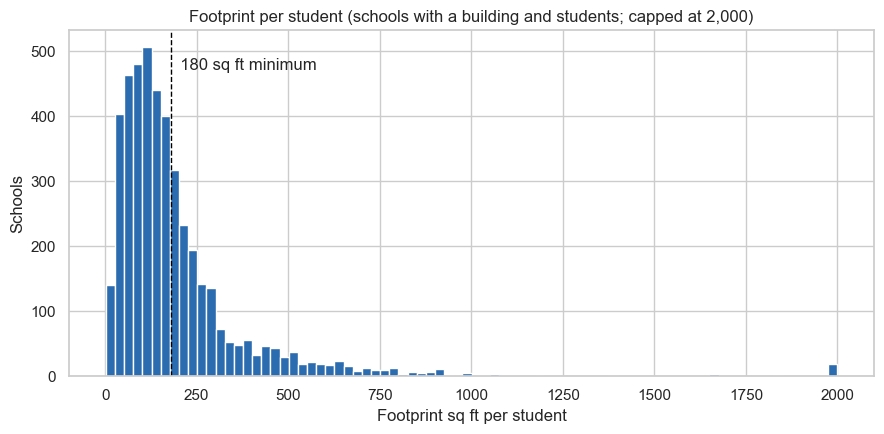

In [12]:
matched = school_sqft[school_sqft["building_found"] & school_sqft["student_count"].gt(0).fillna(False)]
sqft_per_student = (matched["footprint_sqft"] / matched["student_count"].astype(float)).clip(upper=2000)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(sqft_per_student, bins=80, color="#2b6cb0")
ax.axvline(MINIMUM_SQFT_PER_STUDENT, color="black", linestyle="--", linewidth=1)
ax.text(MINIMUM_SQFT_PER_STUDENT, ax.get_ylim()[1] * 0.92, "  180 sq ft minimum", va="top")
ax.set_title("Footprint per student (schools with a building and students; capped at 2,000)")
ax.set_xlabel("Footprint sq ft per student")
ax.set_ylabel("Schools")
plt.tight_layout()
plt.show()

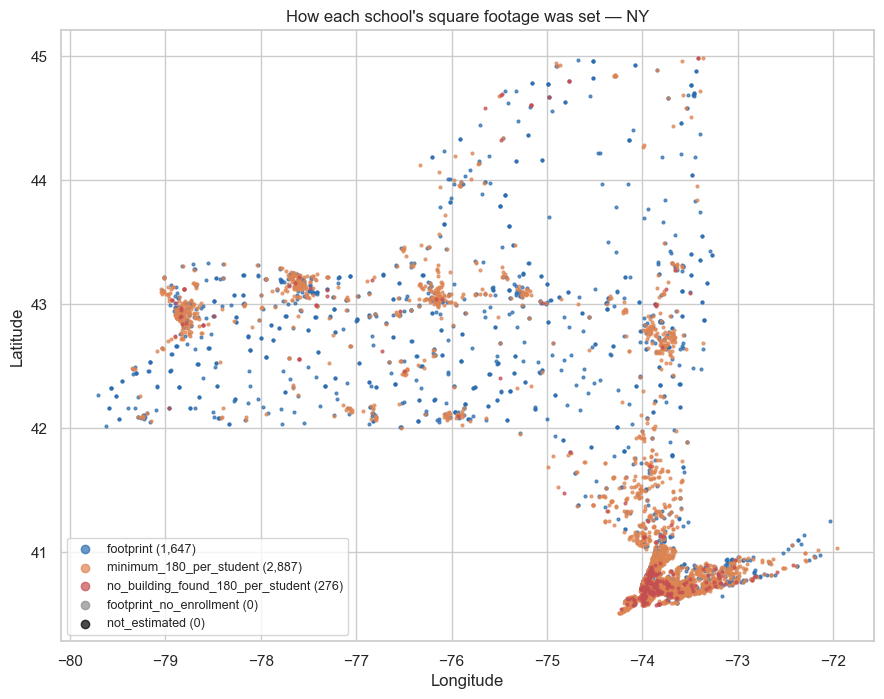

In [13]:
fig, ax = plt.subplots(figsize=(9, 9))
colors = {
    "footprint": "#2b6cb0",
    "minimum_180_per_student": "#dd8452",
    "no_building_found_180_per_student": "#c44e52",
    "footprint_no_enrollment": "#8c8c8c",
    "not_estimated": "#000000",
}
for method, color in colors.items():
    subset = school_sqft[school_sqft["sqft_method"] == method]
    ax.scatter(
        subset["longitude"],
        subset["latitude"],
        s=4,
        color=color,
        label=f"{method} ({len(subset):,})",
        alpha=0.7,
    )
ax.set_title(f"How each school's square footage was set — {scope_label}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1.3)
ax.legend(loc="lower left", markerscale=3, fontsize=9)
plt.tight_layout()
plt.show()

## 9. Save output

`school_sqft_2024_25_<scope>.csv` — one row per operational school in scope:

| Column | Meaning |
|---|---|
| `school_id`, `school_name`, `admin_state`, `location_state`, `level`, `student_count` | From Step 1 (`location_state` = state the school physically sits in) |
| `footprint_file_available` | Microsoft has a footprint file for this school's state |
| `building_found` | A building outline contains the school's point |
| `footprint_sqft` | Roof area of that building (one floor), square feet |
| `building_capture_dates` | Imagery date(s) the building was drawn from; blank when unknown |
| `nearest_building_distance_m`, `nearest_building_sqft` | Only when `building_found` is false: distance to and size of the nearest building within 100 m (call-out 3; not used in the estimate) |
| `schools_at_same_point` | Number of operational schools sharing this exact point (call-out 2) |
| `estimated_sqft` | Square footage to use downstream; blank when it cannot be estimated |
| `sqft_method` | Which rule set `estimated_sqft` (section 6) |

In [14]:
OUTPUT_COLUMNS = [
    "school_id",
    "school_name",
    "admin_state",
    "location_state",
    "level",
    "student_count",
    "footprint_file_available",
    "building_found",
    "footprint_sqft",
    "building_capture_dates",
    "nearest_building_distance_m",
    "nearest_building_sqft",
    "schools_at_same_point",
    "estimated_sqft",
    "sqft_method",
]
output_path = INTERIM_DIR / f"school_sqft_2024_25_{scope_label}.csv"
school_sqft[OUTPUT_COLUMNS].round(
    {"footprint_sqft": 1, "estimated_sqft": 1, "nearest_building_distance_m": 1, "nearest_building_sqft": 1}
).to_csv(output_path, index=False)

reread = pd.read_csv(output_path, dtype={"school_id": str})
check(
    len(reread) == len(school_sqft) and reread["school_id"].equals(school_sqft["school_id"]),
    "Saved square-footage file does not match what was computed.",
)
print(f"Saved {len(reread):,} schools to {output_path.relative_to(PROJECT_ROOT)}")

Saved 4,810 schools to data/interim/school_sqft_2024_25_NY.csv
